In [1]:
import pandas as pd
import numpy as np
from collections import Counter

# Assuming we have a dataset already loaded with a 'formula' column
# Sample data for demonstration (this should be replaced with actual data)


# Convert to DataFrame
# df = pd.read_csv('suggested_candidates.csv')
df = pd.read_csv('3d_metal_todo.csv')

# Function to parse formulas and extract element weights
def parse_formula(formula):
    import re
    pattern = r"([A-Za-z]+)(\d+\.\d+)"  # Match element and its weight
    return re.findall(pattern, formula)

# Extract all elements and their weights
element_weights = []
for formula in df['Formula']:
    element_weights.extend(parse_formula(formula))

# Calculate frequency of elements and their average weights
elements = [elem for elem, _ in element_weights]
weights = [float(weight) for _, weight in element_weights]
element_freq = Counter(elements)

# Prepare results
element_analysis = pd.DataFrame({
    "Element": list(element_freq.keys()),
    "Frequency": list(element_freq.values()),
    "Average Weight": [sum(float(w) for e, w in element_weights if e == elem) / element_freq[elem] 
                       for elem in element_freq.keys()]
})

# import ace_tools as tools; tools.display_dataframe_to_user(name="Element Analysis", dataframe=element_analysis)
element_analysis = element_analysis.sort_values(by=['Frequency'], ascending=False)
element_analysis.to_csv('Pareto_element_analysis.csv', index=False)
element_analysis

,Element,Frequency,Average Weight
1,Fe,47,0.336362
4,Cu,47,0.154255
2,Co,46,0.328087
3,Ni,33,0.112727
6,Zn,32,0.131781
0,Mn,21,0.067810
7,Sc,9,0.090444
9,Ti,8,0.090250
8,V,4,0.113000
5,Cr,3,0.166667


In [2]:
# ! pip3 install plotly --user
# ! pip3 install plotly --upgrade --user
# ! pip3 install -U kaleido --user
! pip3 show kaleido

Name: kaleido
Version: 0.2.1
Summary: Static image export for web-based visualization libraries with zero dependencies
Home-page: UNKNOWN
Author: Jon Mease
Author-email: jon@plotly.com
License: MIT
Location: /work/home/md88vyxi/.local/lib/python3.6/site-packages
Requires: 


In [3]:
import plotly.express as px
from sklearn.cluster import KMeans
import plotly.io as pio

X = element_analysis[['Frequency', 'Average Weight']]
# 应用 K-Means 聚类
kmeans = KMeans(n_clusters=5, random_state=42)
element_analysis['Cluster'] = kmeans.fit_predict(X)

element_analysis['Cluster'] = element_analysis['Cluster'] + 1
data_sorted = element_analysis.sort_values(by='Cluster')

# 3. 创建太阳爆炸图
fig_cluster = px.sunburst(
    data_sorted,
    path=['Cluster', 'Element'],  # 第一层是 Cluster，第二层是 Element
    values='Frequency',  # 根据 Frequency 决定每部分大小
    color='Average Weight',  # 使用 Average Weight 着色
    color_continuous_scale='Viridis',
    title='Sunburst Chart: Clusters, Elements, and Average Weight',
    labels={'Cluster': 'Cluster', 'Average Weight': 'Avg Weight'}
)

# 优化图的布局
fig_cluster.update_layout(margin=dict(t=50, l=25, r=25, b=25))

# 4. 保存太阳爆炸图为 HTML 文件
output_cluster_path = "Sunburst_Cluster_Element_Analysis.html"
# fig_cluster.write_html(output_cluster_path)

pio.write_image(fig_cluster, 'sunburst.svg')

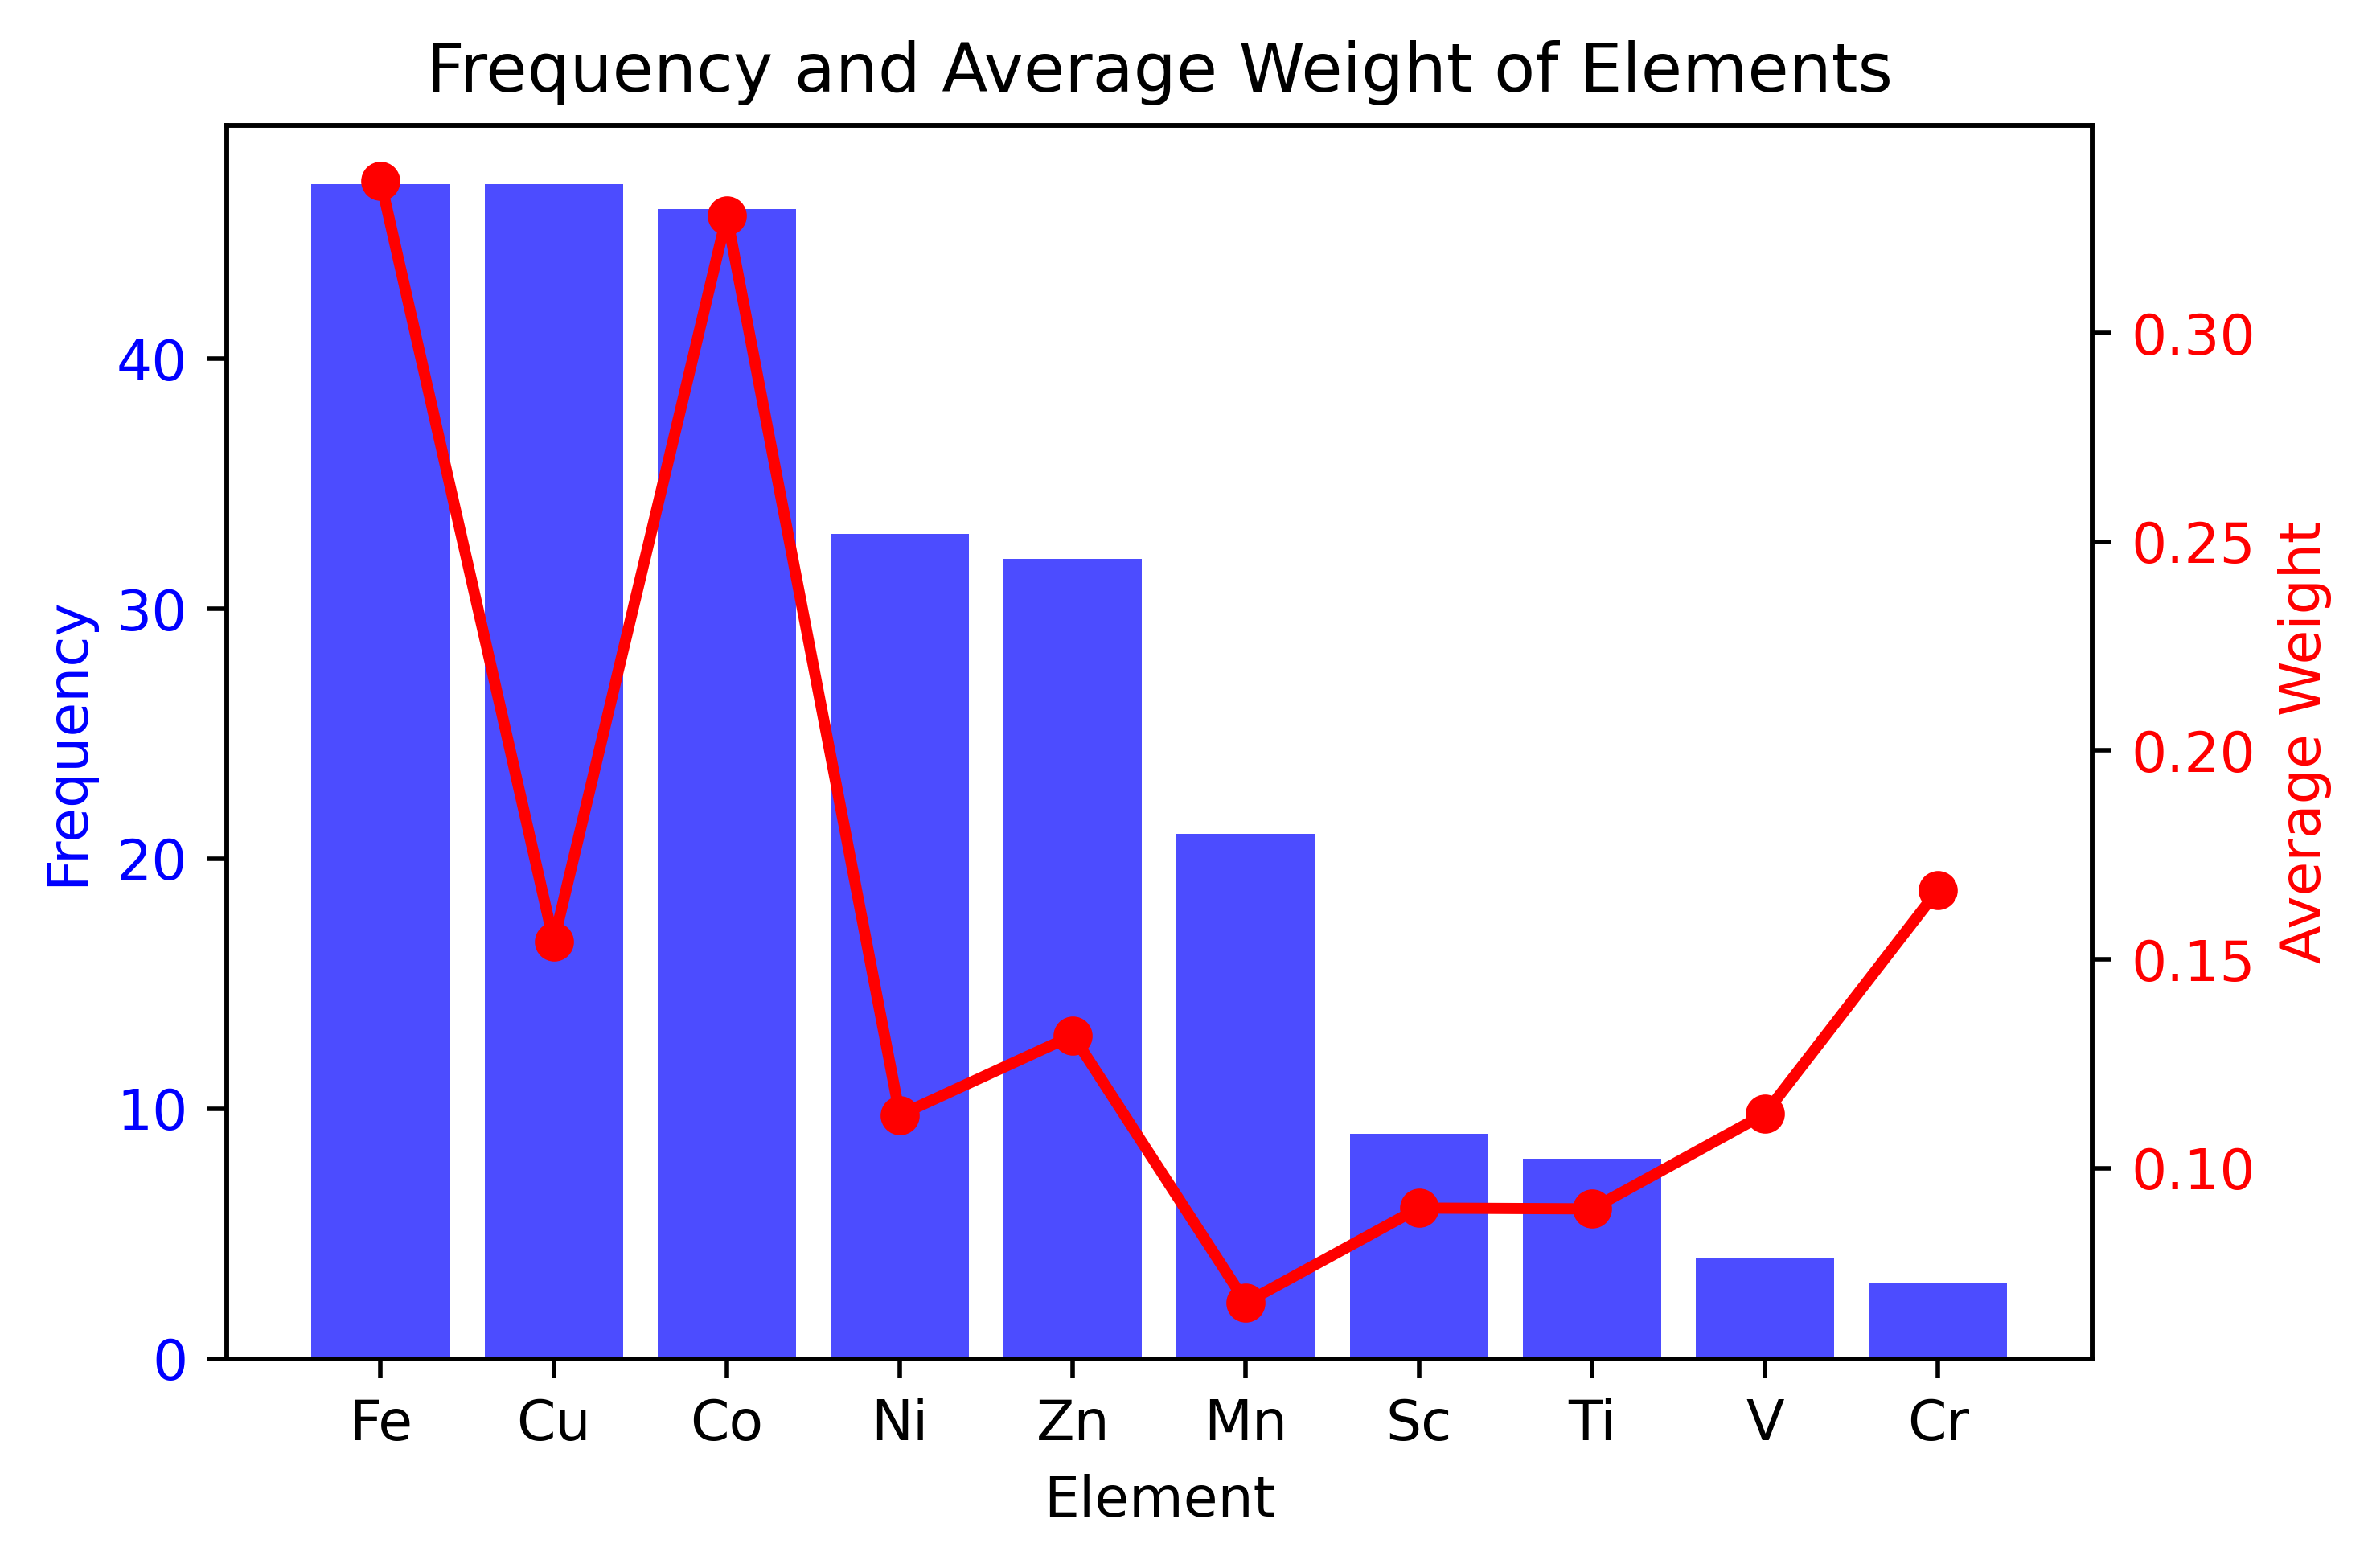

In [4]:
import matplotlib.pyplot as plt
# Creating an adjacent bar plot for Frequency and Average Weight
fig, ax1 = plt.subplots(dpi=500)

# Plot Frequency on the left y-axis
ax1.bar(element_analysis['Element'], element_analysis['Frequency'], alpha=0.7, label='Frequency', color='blue')
ax1.set_xlabel('Element')
ax1.set_ylabel('Frequency', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Plot Average Weight on the right y-axis
ax2 = ax1.twinx()
ax2.plot(element_analysis['Element'], element_analysis['Average Weight'], color='red', marker='o', label='Average Weight', linewidth=2)
ax2.set_ylabel('Average Weight', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Title and layout
plt.title('Frequency and Average Weight of Elements')
fig.tight_layout()

plt.show()

In [5]:
import pandas as pd
import numpy as np
from collections import Counter

# Assuming we have a dataset already loaded with a 'formula' column
# Sample data for demonstration (this should be replaced with actual data)


# Convert to DataFrame
df = pd.read_csv('suggested_candidates.csv')

# Function to parse formulas and extract element weights
def parse_formula(formula):
    import re
    pattern = r"([A-Za-z]+)(\d+\.\d+)"  # Match element and its weight
    return re.findall(pattern, formula)

# Extract all elements and their weights
element_weights = []
for formula in df['Formula']:
    element_weights.extend(parse_formula(formula))

# Calculate frequency of elements and their average weights
elements = [elem for elem, _ in element_weights]
weights = [float(weight) for _, weight in element_weights]
element_freq = Counter(elements)

# Create a DataFrame to store element weights
element_weight_df = pd.DataFrame({
    "Element": elements,
    "Weight": weights
})

# Group by Element to get statistics
element_stats = element_weight_df.groupby('Element').agg(
    Average_Weight=('Weight', 'mean'),          # Mean of weights
    Standard_Deviation=('Weight', 'std'),       # Standard deviation of weights
    Min_Weight=('Weight', 'min'),               # Minimum weight
    Max_Weight=('Weight', 'max')                # Maximum weight
).reset_index()

# Merge the statistics with the element frequency
element_analysis = pd.merge(element_analysis, element_stats, on="Element")
element_analysis

# # Prepare results
# element_analysis = pd.DataFrame({
#     "Element": list(element_freq.keys()),
#     "Frequency": list(element_freq.values()),
#     "Average Weight": [sum(float(w) for e, w in element_weights if e == elem) / element_freq[elem] 
#                        for elem in element_freq.keys()]
# })

# # import ace_tools as tools; tools.display_dataframe_to_user(name="Element Analysis", dataframe=element_analysis)
# element_analysis = element_analysis.sort_values(by=['Frequency'], ascending=False)
# element_analysis.to_csv('Pareto_element_analysis.csv', index=False)
# element_analysis

,Element,Frequency,Average Weight,Cluster,Average_Weight,Standard_Deviation,Min_Weight,Max_Weight
0,Fe,47,0.336362,2,0.267806,0.154311,0.004,0.802
1,Cu,47,0.154255,2,0.210631,0.124580,0.003,0.824
2,Co,46,0.328087,2,0.260412,0.141792,0.003,0.772
3,Ni,33,0.112727,3,0.205624,0.119157,0.003,0.761
4,Zn,32,0.131781,3,0.192660,0.119356,0.003,0.725
5,Mn,21,0.067810,4,0.157839,0.096373,0.002,0.753
6,Sc,9,0.090444,1,0.167980,0.107324,0.003,0.751
7,Ti,8,0.090250,1,0.168640,0.098600,0.002,0.693
8,V,4,0.113000,5,0.183653,0.113465,0.002,0.719
9,Cr,3,0.166667,5,0.184740,0.116707,0.003,0.757


In [6]:
# Function to parse formula and extract elements
import re

def parse_formula(formula):
    """Parse a chemical formula into a dictionary of elements and proportions."""
    parsed = re.findall(r'([A-Z][a-z]*)([0-9\.]*)', formula)
    return {element: float(amount) if amount else 1.0 for element, amount in parsed}

# Parse the formulas in the dataset
parsed_formulas = df['Formula'].apply(parse_formula)

# Create a DataFrame where each column is an element and values are proportions
element_data = pd.DataFrame(parsed_formulas.tolist()).fillna(0)

# Identify unique element combinations
element_combinations = parsed_formulas.apply(lambda x: tuple(sorted(x.keys())))
combination_counts = element_combinations.value_counts()
combination_counts = combination_counts.reset_index().rename(columns={'index': 'Combination', 0: 'Frequency'})
display(combination_counts)
combination_counts.head(10).to_csv('Pareto_combination_counts.csv', index=False)

# # Display the unique combinations and their frequencies
# import ace_tools as tools; tools.display_dataframe_to_user(
#     name="Unique Element Combinations and Frequencies",
#     dataframe=combination_counts.reset_index().rename(columns={'index': 'Combination', 0: 'Frequency'})
# )

# # Compute statistics for individual elements
# element_statistics = element_data.describe()

# # Display the element statistics to the user
# tools.display_dataframe_to_user(name="Element Proportions Statistics", dataframe=element_statistics)


,Combination,Formula
0,"(Co, Cr, Ni, Sc, Zn)",250
1,"(Cr, Cu, Ni, Sc, Ti)",248
2,"(Cr, Mn, Sc, Ti, V)",247
3,"(Cu, Fe, Ni, Ti, Zn)",247
4,"(Co, Cu, Mn, Ti, V)",246
...,...,...
247,"(Cr, Cu, Fe, Sc, V)",198
248,"(Cr, Cu, Mn, Ni, V)",195
249,"(Co, Fe, Mn, Sc, Ti)",195
250,"(Cu, Mn, Ni, Ti, Zn)",192


In [7]:
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Function to parse formula and extract elements and their proportions
def parse_formula(formula):
    return re.findall(r'([A-Z][a-z]*)([0-9\.]*)', formula)

# Expand the formula into individual elements and their proportions
expanded_data = []
for formula in df['Formula']:
    parsed = parse_formula(formula)
    expanded_data.append({element: float(amount) if amount else 1.0 for element, amount in parsed})

# Convert to DataFrame for easier analysis
expanded_df = pd.DataFrame(expanded_data).fillna(0)

# Summarize the occurrence and distribution of elements
element_summary = expanded_df.sum().sort_values(ascending=False)

# Display the element summary to the user
# tools.display_dataframe_to_user(name="Elemental Distribution Analysis", dataframe=element_summary.reset_index().rename(columns={"index": "Element", 0: "Total Proportion"}))

display(expanded_df.head())

# Combine the expanded elemental data with the material properties
combined_data = pd.concat([expanded_df, df[['M_s', 'T_C', 'Pugh', 'Cauchy', 'pareto']]], axis=1)

# Compute correlations between elements and material properties
correlation_matrix = combined_data.corr()

# Extract correlations of elements with material properties
element_property_correlation = correlation_matrix.loc[expanded_df.columns, ['M_s', 'T_C', 'Pugh', 'Cauchy', 'pareto']]
element_property_correlation = element_property_correlation.sort_values(by=['pareto'],ascending=False)
element_property_correlation.to_csv('Pareto_correlation_element.csv')
display(element_property_correlation)
# df = element_property_correlation[['M_s', 'T_C', 'Pugh', 'Cauchy']]
df = element_property_correlation
# Display the correlation analysis to the user
# tools.display_dataframe_to_user(name="Element-Property Correlation Analysis", dataframe=element_property_correlation)

plt.figure(figsize=(8, 6), dpi=500)
sns.heatmap(df, annot=True, cmap='coolwarm', cbar=True, fmt=".3f", linewidths=0.5)
# plt.title("Heatmap of Material Properties")
# plt.xlabel("Properties")
# plt.ylabel("Elements")
plt.tight_layout()
plt.show()



,Mn,Fe,Co,Ni,Cu,Cr,Zn,Sc,V,Ti
0,0.087,0.592,0.208,0.054,0.059,0.000,0.000,0.000,0.0,0.0
1,0.000,0.336,0.000,0.107,0.249,0.026,0.282,0.000,0.0,0.0
2,0.054,0.491,0.343,0.011,0.101,0.000,0.000,0.000,0.0,0.0
3,0.000,0.302,0.072,0.095,0.262,0.000,0.269,0.000,0.0,0.0
4,0.000,0.067,0.150,0.000,0.356,0.000,0.356,0.071,0.0,0.0


KeyError: "None of [Index(['M_s', 'T_C', 'Pugh', 'Cauchy', 'pareto'], dtype='object')] are in the [columns]"